# 🎓 FEEDBACK PRIZE: Evaluating Student Writing
# EDA

### Set up project paths and load environment variables (Kaggle credentials) from .env.

In [1]:
import os
import sys
from pathlib import Path
from dotenv import load_dotenv

IS_MAC = sys.platform == 'darwin'
IN_COLAB = os.path.exists('/content') and not IS_MAC

user, token = None, None

if IN_COLAB:
    try:
        from google.colab import userdata
        user = userdata.get('KAGGLE_USERNAME')
        token = userdata.get('KAGGLE_API_TOKEN')
        print("🔑 Loaded credentials from Colab Secrets")
    except Exception:
        print("⚠️ Colab Secrets not set up yet")
else:
    cwd = Path.cwd()
    ROOT_DIR = cwd.parent if cwd.name == 'notebooks' else cwd
    load_dotenv(ROOT_DIR / ".env")
    user = os.getenv("KAGGLE_USERNAME")
    token = os.getenv("KAGGLE_API_TOKEN")
    print(f"📄 Loaded credentials from local .env")

if not user or not token:
    import getpass
    print("Falling back to manual input:")
    user = input("Kaggle username: ")
    token = getpass.getpass("Kaggle API token: ")

os.environ["KAGGLE_USERNAME"] = user
os.environ["KAGGLE_API_TOKEN"] = token
print(f"🚀 Credentials for '{user}' are active.")

📄 Loaded credentials from local .env
🚀 Credentials for 'veronicaterterian' are active.


### Download the competition dataset from Kaggle (skips download if already present) and load it into a DataFrame.

In [ ]:
import os
import sys
from pathlib import Path
import kagglehub
import shutil
import pandas as pd

# Determine project root depending on platform
IS_MAC = sys.platform == 'darwin'
IN_COLAB = os.path.exists('/content') and not IS_MAC

if IN_COLAB:
    ROOT_DIR = Path("/content")
else:
    cwd = Path.cwd()
    ROOT_DIR = cwd.parent if cwd.name == 'notebooks' else cwd

DATA_RAW_DIR = ROOT_DIR / "data" / "raw"
os.makedirs(DATA_RAW_DIR, exist_ok=True)

print(f"📁 Data folder: {DATA_RAW_DIR}")

def setup_project_data(output_path):
    if (output_path / "train.csv").exists():
        print("✅ Data already downloaded.")
        return

    user = os.getenv("KAGGLE_USERNAME")
    token = os.getenv("KAGGLE_API_TOKEN")

    if not user or not token:
        raise RuntimeError("❌ Kaggle credentials not set. Run the credentials cell above first.")

    os.environ["KAGGLE_USERNAME"] = user
    os.environ["KAGGLE_KEY"] = token  # kagglehub expects KAGGLE_KEY specifically

    print("⏳ Downloading from Kaggle...")
    try:
        tmp_cache = kagglehub.competition_download('feedback-prize-2021')
    except Exception as e:
        print(f"❌ Download failed: {e}")
        raise

    for item in os.listdir(tmp_cache):
        src = os.path.join(tmp_cache, item)
        dst = output_path / item
        if os.path.isdir(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)
        else:
            shutil.copy2(src, dst)
    print("🚀 Download complete!")

setup_project_data(DATA_RAW_DIR)

train_df = pd.read_csv(DATA_RAW_DIR / "train.csv")
print(f"📊 Rows loaded: {len(train_df)}")

### Explore class balance and text length distribution across discourse types.


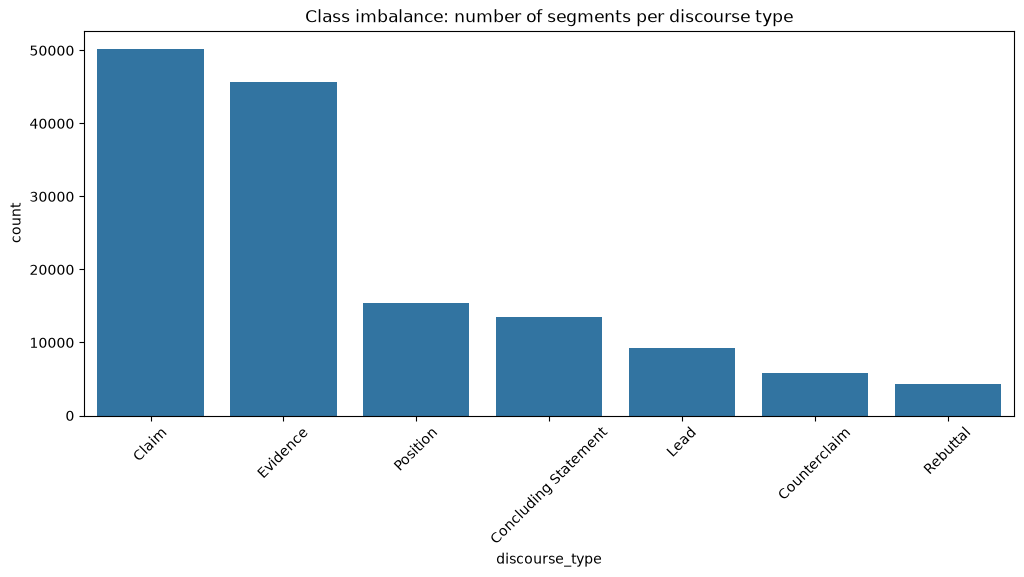

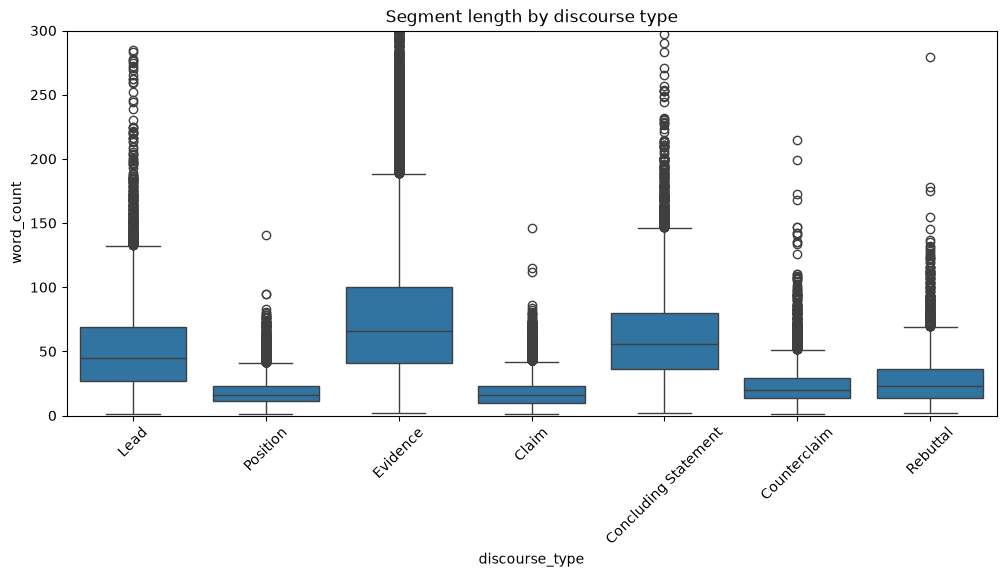

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
sns.countplot(data=train_df, x='discourse_type', order=train_df['discourse_type'].value_counts().index)
plt.title("Class imbalance: number of segments per discourse type")
plt.xticks(rotation=45)
plt.show()

# Calculate word counts
train_df['word_count'] = train_df['discourse_text'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(12, 5))
sns.boxplot(data=train_df, x='discourse_type', y='word_count')
plt.title("Segment length by discourse type")
plt.xticks(rotation=45)
plt.ylim(0, 300)
plt.show()

### Aggregate view: how many essays, how many segments per essay, and overall essay length.

📄 Unique essays: 15594
🧩 Total segments: 144293
📊 Avg segments per essay: 9.3


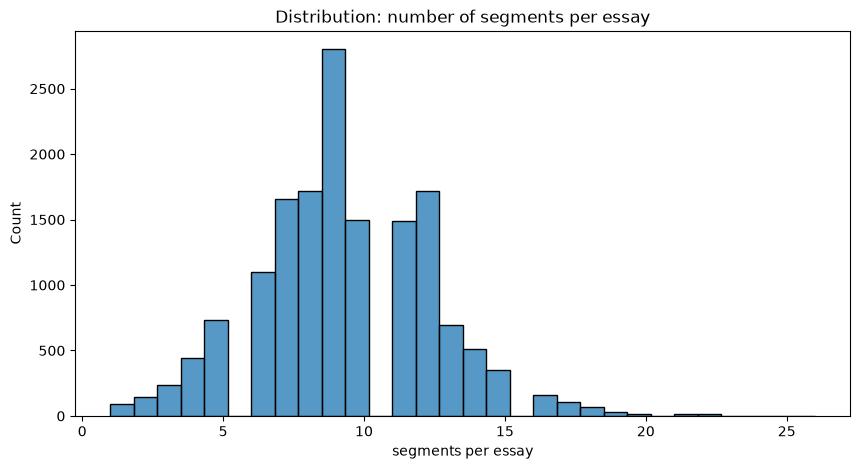

count    15594.000000
mean         9.253110
std          3.124329
min          1.000000
25%          7.000000
50%          9.000000
75%         11.000000
max         26.000000
dtype: float64


In [4]:
# Number of unique essays
n_essays = train_df['id'].nunique()
n_segments = len(train_df)
print(f"📄 Unique essays: {n_essays}")
print(f"🧩 Total segments: {n_segments}")
print(f"📊 Avg segments per essay: {n_segments / n_essays:.1f}")

# Segments per essay distribution
segments_per_essay = train_df.groupby('id').size()

plt.figure(figsize=(10, 5))
sns.histplot(segments_per_essay, bins=30)
plt.title("Distribution: number of segments per essay")
plt.xlabel("segments per essay")
plt.show()

print(segments_per_essay.describe())

### Essay length (full text), to check whether essays fit within typical transformer token limits (e.g. 512 tokens).

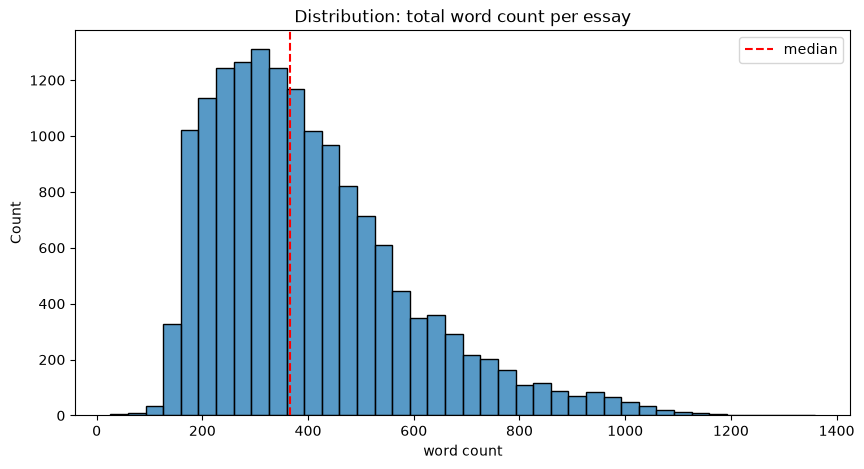

count    15594.000000
mean       401.738297
std        186.001121
min         26.000000
25%        263.000000
50%        365.000000
75%        498.000000
max       1359.000000
Name: word_count, dtype: float64

⚠️ Essays over 512 words: 3577 (22.9%)


In [5]:
# Reconstruct full essay length by summing segment word counts
essay_word_count = train_df.groupby('id')['word_count'].sum()

plt.figure(figsize=(10, 5))
sns.histplot(essay_word_count, bins=40)
plt.title("Distribution: total word count per essay")
plt.xlabel("word count")
plt.axvline(essay_word_count.median(), color='red', linestyle='--', label='median')
plt.legend()
plt.show()

print(essay_word_count.describe())
print(f"\n⚠️ Essays over 512 words: {(essay_word_count > 512).sum()} ({(essay_word_count > 512).mean()*100:.1f}%)")

### Sanity checks: missing values, duplicate rows, and unexpected discourse types.

In [6]:
print("Missing values per column:")
print(train_df.isnull().sum())
print(f"\nDuplicate rows: {train_df.duplicated().sum()}")
print(f"\nDiscourse types found: {train_df['discourse_type'].unique()}")

Missing values per column:
id                    0
discourse_id          0
discourse_start       0
discourse_end         0
discourse_text        0
discourse_type        0
discourse_type_num    0
predictionstring      0
word_count            0
dtype: int64

Duplicate rows: 0

Discourse types found: <ArrowStringArray>
[                'Lead',             'Position',             'Evidence',
                'Claim', 'Concluding Statement',         'Counterclaim',
             'Rebuttal']
Length: 7, dtype: str


### Visualize one full essay with its discourse segments highlighted, to build intuition before modeling.

In [7]:
sample_id = train_df['id'].iloc[0]
sample_essay = train_df[train_df['id'] == sample_id].sort_values('discourse_start')

print(f"Essay ID: {sample_id}")
print(f"Number of segments: {len(sample_essay)}\n")

for _, row in sample_essay.iterrows():
    print(f"[{row['discourse_type']}] {row['discourse_text'][:100]}...\n")

Essay ID: 423A1CA112E2
Number of segments: 10

[Lead] Modern humans today are always on their phone. They are always on their phone more than 5 hours a da...

[Position] They are some really bad consequences when stuff happens when it comes to a phone....

[Evidence] Some certain areas in the United States ban phones from class rooms just because of it. ...

[Evidence] When people have phones, they know about certain apps that they have .Apps like Facebook Twitter Ins...

[Claim] Driving is one of the way how to get around. People always be on their phones while doing it. Which ...

[Evidence] That's why there's a thing that's called no texting while driving. That's a really important thing t...

[Evidence] Sometimes on the news there is either an accident or a suicide. It might involve someone not looking...

[Claim] Phones are fine to use and it's also the best way to come over help....

[Evidence] If you go through a problem and you can't find help you ,always have a phone there wit

### Conclusions

With about 25% of the essays exceeding the 512-token limit—especially after subword tokenization—we have to decide on a long-context strategy now. It’s not something we can push off until after the baseline; it's a core design choice we need to make upfront.

**Options:**

*   **Truncation** — simply cutting the text at 512 tokens. You will lose data in longer essays, risking the loss of the ending where the *Concluding Statement* is often located.

*   **Sliding window / stride** — splitting long essays into overlapping windows and then aggregating (stitching) the predictions together.

*   **Longformer / BigBird** — models with an extended context (up to 4096 tokens). These solve the problem at the architectural level but are more computationally expensive to train.